In [1]:
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [2]:
# import numpy
#
# from util.data_aquisition import generate

In [3]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2015-2016
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2016-2017
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2017-2018
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2018-2019


In [4]:
df = engineered_data_frame(data)

C:\Users\GM\Desktop\IFT-6758\notebooks\util\engineered_data_frame.py:75: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [5]:
df

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,Time_Between_Events,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed
0,2015020001,R,7,6,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,11,55.0,-94.0,154.275727,34.525353,False,10.007980,0.00000,10.007980,14.025066
1,2015020001,R,9,8,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Giveaway,Snap Shot,...,7,79.0,37.0,50.477718,10.000000,False,0.000000,0.00000,0.000000,7.211103
2,2015020001,R,10,9,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Shot,Snap Shot,...,1,75.0,79.0,4.123106,14.035669,True,-4.085617,0.00000,-4.085617,4.123106
3,2015020001,R,13,12,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,18,55.0,91.0,79.605276,49.517674,False,-46.636577,0.00000,-46.636577,4.422515
4,2015020001,R,21,20,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Faceoff,Tip-In,...,5,61.0,69.0,22.472205,28.017851,False,-2.045408,0.00000,-2.045408,4.494441
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021271,R,276,275,San Jose Sharks,left,Colorado Avalanche,Shot,Giveaway,Slap Shot,...,33,67.0,29.0,66.030296,29.068884,False,-40.815084,0.00000,-40.815084,2.000918
311102,2018021271,R,281,280,San Jose Sharks,left,Colorado Avalanche,Shot,Faceoff,Wrist Shot,...,29,78.0,69.0,24.698178,11.045361,False,5.194429,0.00000,5.194429,0.851661
311103,2018021271,R,291,290,San Jose Sharks,left,Colorado Avalanche,Shot,Missed Shot,Wrist Shot,...,19,82.0,71.0,12.529964,12.206556,False,55.007980,0.00000,55.007980,0.659472
311104,2018021271,R,292,291,San Jose Sharks,left,Colorado Avalanche,Shot,Shot,Wrist Shot,...,1,81.0,82.0,9.055385,8.062258,True,7.125016,55.00798,-47.882963,9.055385


In [6]:
import pandas as pd
import numpy as np
import math
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.model_selection import KFold
from sklearn.calibration import calibration_curve, CalibrationDisplay
from scipy.stats import percentileofscore
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import StandardScaler

In [7]:
df

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,Time_Between_Events,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed
0,2015020001,R,7,6,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,11,55.0,-94.0,154.275727,34.525353,False,10.007980,0.00000,10.007980,14.025066
1,2015020001,R,9,8,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Giveaway,Snap Shot,...,7,79.0,37.0,50.477718,10.000000,False,0.000000,0.00000,0.000000,7.211103
2,2015020001,R,10,9,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Shot,Snap Shot,...,1,75.0,79.0,4.123106,14.035669,True,-4.085617,0.00000,-4.085617,4.123106
3,2015020001,R,13,12,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,18,55.0,91.0,79.605276,49.517674,False,-46.636577,0.00000,-46.636577,4.422515
4,2015020001,R,21,20,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Faceoff,Tip-In,...,5,61.0,69.0,22.472205,28.017851,False,-2.045408,0.00000,-2.045408,4.494441
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021271,R,276,275,San Jose Sharks,left,Colorado Avalanche,Shot,Giveaway,Slap Shot,...,33,67.0,29.0,66.030296,29.068884,False,-40.815084,0.00000,-40.815084,2.000918
311102,2018021271,R,281,280,San Jose Sharks,left,Colorado Avalanche,Shot,Faceoff,Wrist Shot,...,29,78.0,69.0,24.698178,11.045361,False,5.194429,0.00000,5.194429,0.851661
311103,2018021271,R,291,290,San Jose Sharks,left,Colorado Avalanche,Shot,Missed Shot,Wrist Shot,...,19,82.0,71.0,12.529964,12.206556,False,55.007980,0.00000,55.007980,0.659472
311104,2018021271,R,292,291,San Jose Sharks,left,Colorado Avalanche,Shot,Shot,Wrist Shot,...,1,81.0,82.0,9.055385,8.062258,True,7.125016,55.00798,-47.882963,9.055385


In [8]:
# Create dataframe having only notnulls for distance and angles, binarize labels
df_model1 = df[df['Distance_Net'].notnull() & df['Angle'].notnull()]
df_model1['Event_Type_Binary'] = df_model1['Event_Type'].apply(lambda row: 1 if row=='Goal' else 0)
df_model1

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\546879660.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_model1['Event_Type_Binary'] = df_model1['Event_Type'].apply(lambda row: 1 if row=='Goal' else 0)


,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed,Event_Type_Binary
0,2015020001,R,7,6,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,55.0,-94.0,154.275727,34.525353,False,10.007980,0.00000,10.007980,14.025066,0
1,2015020001,R,9,8,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Giveaway,Snap Shot,...,79.0,37.0,50.477718,10.000000,False,0.000000,0.00000,0.000000,7.211103,0
2,2015020001,R,10,9,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Shot,Snap Shot,...,75.0,79.0,4.123106,14.035669,True,-4.085617,0.00000,-4.085617,4.123106,0
3,2015020001,R,13,12,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,55.0,91.0,79.605276,49.517674,False,-46.636577,0.00000,-46.636577,4.422515,0
4,2015020001,R,21,20,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Faceoff,Tip-In,...,61.0,69.0,22.472205,28.017851,False,-2.045408,0.00000,-2.045408,4.494441,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021271,R,276,275,San Jose Sharks,left,Colorado Avalanche,Shot,Giveaway,Slap Shot,...,67.0,29.0,66.030296,29.068884,False,-40.815084,0.00000,-40.815084,2.000918,0
311102,2018021271,R,281,280,San Jose Sharks,left,Colorado Avalanche,Shot,Faceoff,Wrist Shot,...,78.0,69.0,24.698178,11.045361,False,5.194429,0.00000,5.194429,0.851661,0
311103,2018021271,R,291,290,San Jose Sharks,left,Colorado Avalanche,Shot,Missed Shot,Wrist Shot,...,82.0,71.0,12.529964,12.206556,False,55.007980,0.00000,55.007980,0.659472,0
311104,2018021271,R,292,291,San Jose Sharks,left,Colorado Avalanche,Shot,Shot,Wrist Shot,...,81.0,82.0,9.055385,8.062258,True,7.125016,55.00798,-47.882963,9.055385,0


In [9]:
df_model1['Event_Type_Binary'].value_counts()

0    281910
1     29175
Name: Event_Type_Binary, dtype: int64

In [10]:
my_data1 = df_model1.values

## Model on distance and angle

In [11]:
df_model1

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed,Event_Type_Binary
0,2015020001,R,7,6,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,55.0,-94.0,154.275727,34.525353,False,10.007980,0.00000,10.007980,14.025066,0
1,2015020001,R,9,8,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Giveaway,Snap Shot,...,79.0,37.0,50.477718,10.000000,False,0.000000,0.00000,0.000000,7.211103,0
2,2015020001,R,10,9,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Shot,Snap Shot,...,75.0,79.0,4.123106,14.035669,True,-4.085617,0.00000,-4.085617,4.123106,0
3,2015020001,R,13,12,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,55.0,91.0,79.605276,49.517674,False,-46.636577,0.00000,-46.636577,4.422515,0
4,2015020001,R,21,20,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Faceoff,Tip-In,...,61.0,69.0,22.472205,28.017851,False,-2.045408,0.00000,-2.045408,4.494441,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021271,R,276,275,San Jose Sharks,left,Colorado Avalanche,Shot,Giveaway,Slap Shot,...,67.0,29.0,66.030296,29.068884,False,-40.815084,0.00000,-40.815084,2.000918,0
311102,2018021271,R,281,280,San Jose Sharks,left,Colorado Avalanche,Shot,Faceoff,Wrist Shot,...,78.0,69.0,24.698178,11.045361,False,5.194429,0.00000,5.194429,0.851661,0
311103,2018021271,R,291,290,San Jose Sharks,left,Colorado Avalanche,Shot,Missed Shot,Wrist Shot,...,82.0,71.0,12.529964,12.206556,False,55.007980,0.00000,55.007980,0.659472,0
311104,2018021271,R,292,291,San Jose Sharks,left,Colorado Avalanche,Shot,Shot,Wrist Shot,...,81.0,82.0,9.055385,8.062258,True,7.125016,55.00798,-47.882963,9.055385,0


In [12]:
my_data1

array([[2015020001, 'R', 7, ..., 10.007979801441339, 14.025066108180845,
        0],
       [2015020001, 'R', 9, ..., 0.0, 7.211102550927978, 0],
       [2015020001, 'R', 10, ..., -4.085616779974877, 4.123105625617661,
        0],
       ...,
       [2018021271, 'R', 291, ..., 55.00797980144134, 0.6594717940074561,
        0],
       [2018021271, 'R', 292, ..., -47.88296345253954, 9.055385138137417,
        0],
       [2018021271, 'R', 298, ..., 14.93141717813755, 48.033553087630544,
        1]], dtype=object)

In [13]:
X = my_data1[:,33], my_data1[:,35]
X = np.asarray(X).transpose()
y = my_data1[:, 39]
y = y.astype('int')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=42)

# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier(tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train, y_train)
# Save model into JSON format.
# reg.save_model("regressor.json")

# lr = LogisticRegression()
# model = lr.fit(X_train,y_train)
print('Accuracy on training data: ', round(model_xgb.score(X_train,y_train),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.68


f1 score: 0.003780718336483932


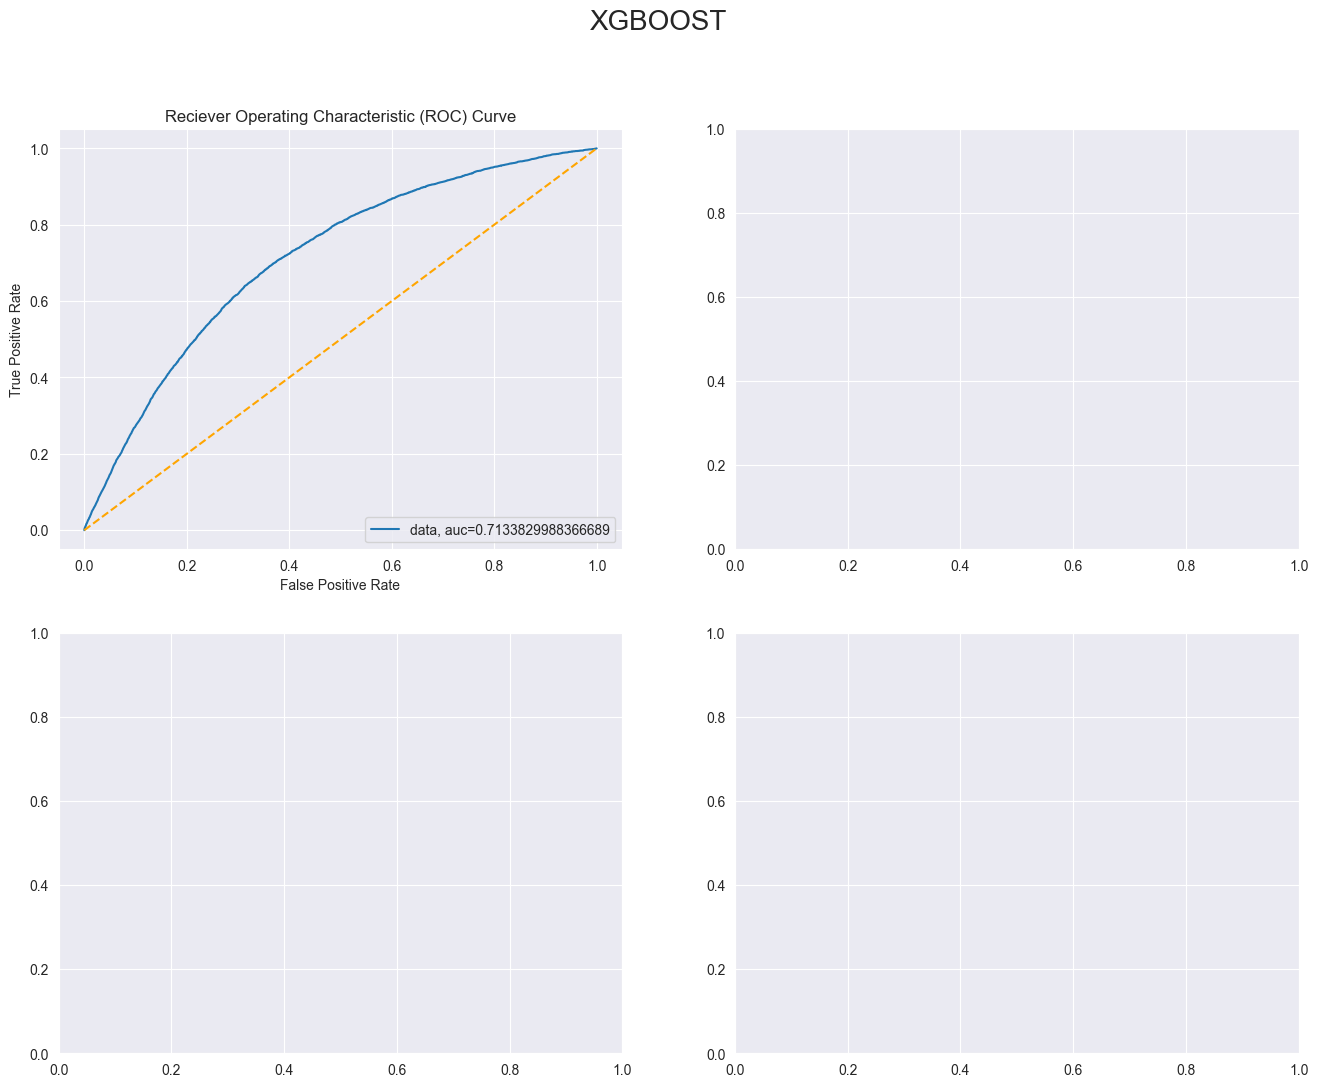

In [14]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_pred_proba = model_xgb.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("XGBOOST", fontsize = 20)
f1 = metrics.f1_score(y_test, model_xgb.predict(X_test))
print(f"f1 score: {f1}")

In [15]:
Dict_proba = {'Goal_Proba': model_xgb.predict_proba(X_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba

df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

df_proba['Goals'] = y_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

df_proba_sorted.reset_index(drop = True, inplace=True)
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted


df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.630505,99.996785,0,0,1,0.000000,0.000000
1,0.630505,99.996785,0,0,2,0.000000,0.000000
2,0.630505,99.996785,1,1,3,0.333333,0.000173
3,0.630505,99.996785,0,1,4,0.250000,0.000173
4,0.630505,99.996785,0,1,5,0.200000,0.000173
...,...,...,...,...,...,...,...
62212,0.001886,0.007233,0,5796,62213,0.093164,1.000000
62213,0.001886,0.007233,0,5796,62214,0.093162,1.000000
62214,0.001886,0.007233,0,5796,62215,0.093161,1.000000
62215,0.001886,0.007233,0,5796,62216,0.093159,1.000000


Text(0.5, 1.0, 'Calibration curve')

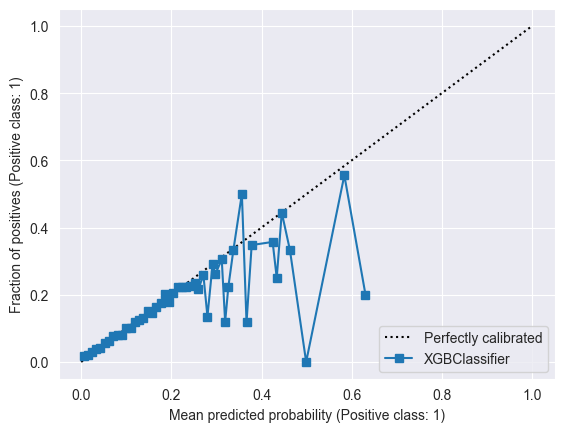

In [16]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")
disp_test = CalibrationDisplay.from_estimator(model_xgb,X_test, y_test, n_bins = 105)
disp_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

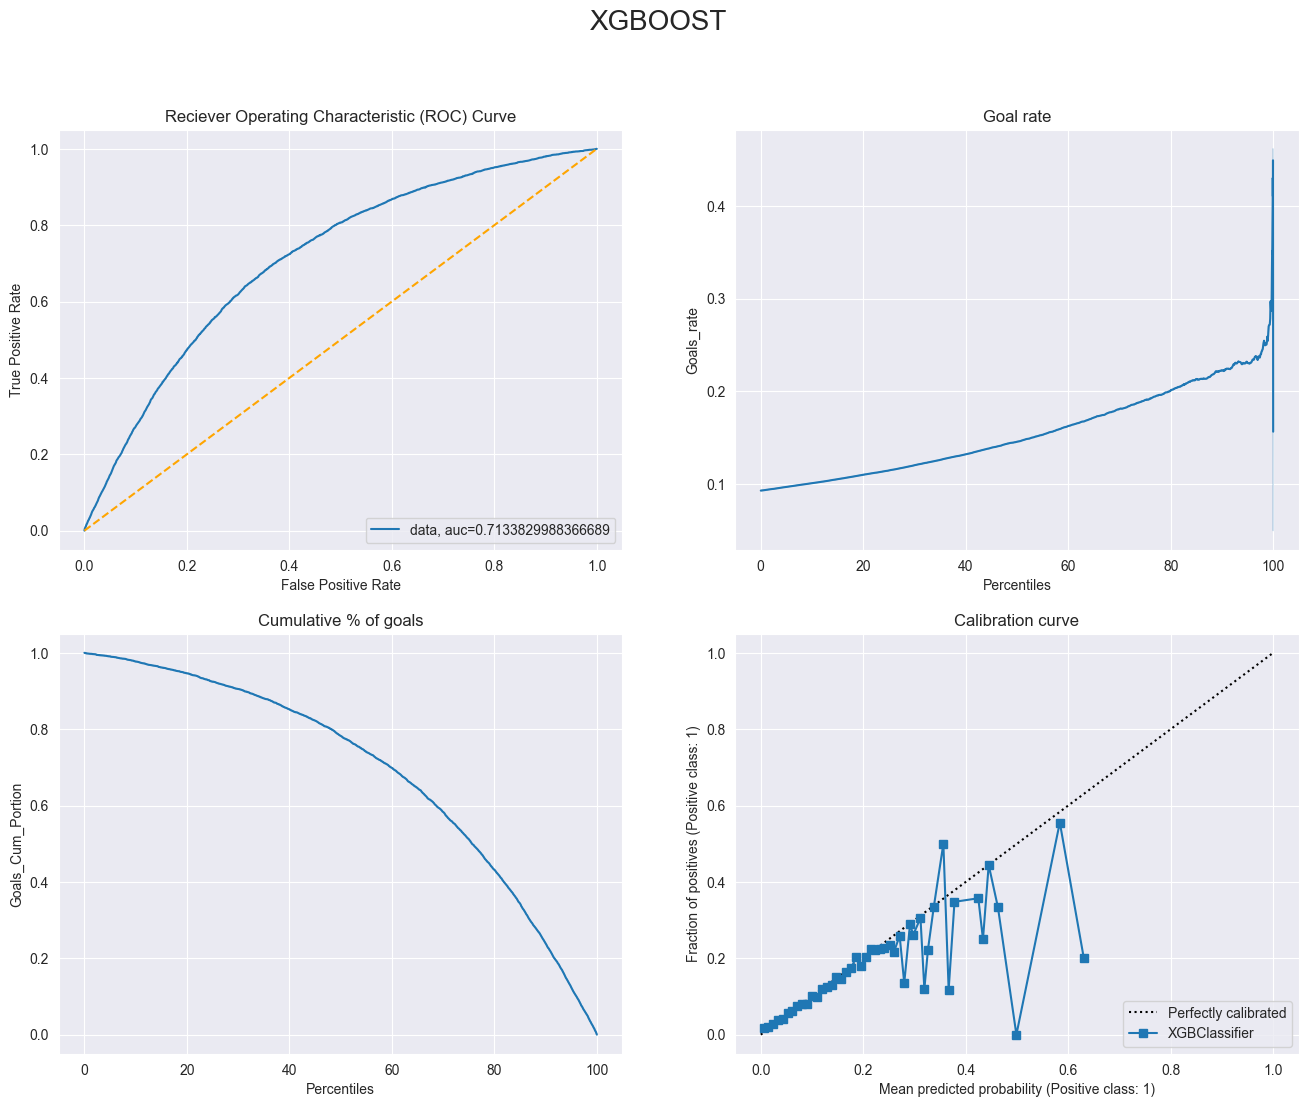

In [17]:
fig

## Part 2

In [18]:
# Create dataframe having only notnulls for all of the following
temp = df[df['Distance_Net'].notnull() & df['Angle'].notnull() & df['Period_Time_Seconds'].notnull() & df['Period'].notnull() & df['X_Transformed'].notnull() & df['Y_Coordinate'].notnull() & df['Shoot_Type'].notnull() & df['Last_Event_Type'].notnull() & df['Last_X_Transformed'].notnull() & df['Last_Coordinate_Y'].notnull() & df['Time_Between_Events'].notnull() & df['Distance_Last_Event'].notnull() & df['Rebond'].notnull() & df['Delta_Angle'].notnull() & df['Speed'].notnull()]
temp['Rebond_Binary'] = df['Rebond'].apply(lambda row: 1 if row else 0)
temp

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\3201754472.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Rebond_Binary'] = df['Rebond'].apply(lambda row: 1 if row else 0)


,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed,Rebond_Binary
0,2015020001,R,7,6,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,55.0,-94.0,154.275727,34.525353,False,10.007980,0.00000,10.007980,14.025066,0
1,2015020001,R,9,8,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Giveaway,Snap Shot,...,79.0,37.0,50.477718,10.000000,False,0.000000,0.00000,0.000000,7.211103,0
2,2015020001,R,10,9,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Shot,Snap Shot,...,75.0,79.0,4.123106,14.035669,True,-4.085617,0.00000,-4.085617,4.123106,1
3,2015020001,R,13,12,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,55.0,91.0,79.605276,49.517674,False,-46.636577,0.00000,-46.636577,4.422515,0
4,2015020001,R,21,20,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Faceoff,Tip-In,...,61.0,69.0,22.472205,28.017851,False,-2.045408,0.00000,-2.045408,4.494441,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021271,R,276,275,San Jose Sharks,left,Colorado Avalanche,Shot,Giveaway,Slap Shot,...,67.0,29.0,66.030296,29.068884,False,-40.815084,0.00000,-40.815084,2.000918,0
311102,2018021271,R,281,280,San Jose Sharks,left,Colorado Avalanche,Shot,Faceoff,Wrist Shot,...,78.0,69.0,24.698178,11.045361,False,5.194429,0.00000,5.194429,0.851661,0
311103,2018021271,R,291,290,San Jose Sharks,left,Colorado Avalanche,Shot,Missed Shot,Wrist Shot,...,82.0,71.0,12.529964,12.206556,False,55.007980,0.00000,55.007980,0.659472,0
311104,2018021271,R,292,291,San Jose Sharks,left,Colorado Avalanche,Shot,Shot,Wrist Shot,...,81.0,82.0,9.055385,8.062258,True,7.125016,55.00798,-47.882963,9.055385,1


In [19]:
temp2 = temp[['Period', 'Period_Time_Seconds', 'Time_Between_Events', 'X_Transformed', 'Last_X_Transformed', 'Y_Coordinate', 'Last_Coordinate_Y', 'Distance_Last_Event', 'Distance_Net', 'Rebond_Binary', 'Delta_Angle', 'Speed']]
# temp2['Event_Type_Binary'] = temp['Event_Type'].apply(lambda row: 1 if row=='Goal' else 0)
temp2

,Period,Period_Time_Seconds,Time_Between_Events,X_Transformed,Last_X_Transformed,Y_Coordinate,Last_Coordinate_Y,Distance_Last_Event,Distance_Net,Rebond_Binary,Delta_Angle,Speed
0,1,51,11,55.0,-94.0,6.0,-34.0,154.275727,34.525353,0,10.007980,14.025066
1,1,65,7,79.0,37.0,0.0,-28.0,50.477718,10.000000,0,0.000000,7.211103
2,1,66,1,75.0,79.0,-1.0,0.0,4.123106,14.035669,1,-4.085617,4.123106
3,1,113,18,55.0,91.0,-36.0,35.0,79.605276,49.517674,0,-46.636577,4.422515
4,1,157,5,61.0,69.0,-1.0,-22.0,22.472205,28.017851,0,-2.045408,4.494441
...,...,...,...,...,...,...,...,...,...,...,...,...
311101,3,937,33,67.0,29.0,-19.0,35.0,66.030296,29.068884,0,-40.815084,2.000918
311102,3,993,29,78.0,69.0,1.0,-22.0,24.698178,11.045361,0,5.194429,0.851661
311103,3,1119,19,82.0,71.0,10.0,4.0,12.529964,12.206556,0,55.007980,0.659472
311104,3,1120,1,81.0,82.0,1.0,10.0,9.055385,8.062258,1,-47.882963,9.055385


In [20]:
df_model2 = temp2.copy()

In [21]:
my_bina = LabelBinarizer()
y = my_bina.fit_transform(temp.Shoot_Type.astype(str))
my_bina.classes_

df_model2['Backhand'] = y[:,0]
df_model2['Deflected'] = y[:,1]
df_model2['Slap_Shot'] = y[:,2]
df_model2['Snap_Shot'] = y[:,3]
df_model2['Tip-In'] = y[:,4]
df_model2['Wrap-Around'] = y[:,5]
df_model2['Wrist_Shot'] = y[:,6]
my_bina.classes_

my_bina = LabelBinarizer()
y = my_bina.fit_transform(temp.Last_Event_Type.astype(str))
my_bina.classes_

df_model2['Blocked_Shot'] = y[:,0]
df_model2['Faceoff'] = y[:,1]
df_model2['Giveaway'] = y[:,2]
df_model2['Goal'] = y[:,3]
df_model2['Hit'] = y[:,4]
df_model2['Missed_Shot'] = y[:,5]
df_model2['Penalty'] = y[:,6]
df_model2['Shot'] = y[:,7]
df_model2['Takeaway'] = y[:,8]
my_bina.classes_

df_model2['Event_Type_Binary'] = temp['Event_Type'].apply(lambda row: 1 if row=='Goal' else 0)

df_model2

,Period,Period_Time_Seconds,Time_Between_Events,X_Transformed,Last_X_Transformed,Y_Coordinate,Last_Coordinate_Y,Distance_Last_Event,Distance_Net,Rebond_Binary,...,Blocked_Shot,Faceoff,Giveaway,Goal,Hit,Missed_Shot,Penalty,Shot,Takeaway,Event_Type_Binary
0,1,51,11,55.0,-94.0,6.0,-34.0,154.275727,34.525353,0,...,0,0,0,0,1,0,0,0,0,0
1,1,65,7,79.0,37.0,0.0,-28.0,50.477718,10.000000,0,...,0,0,1,0,0,0,0,0,0,0
2,1,66,1,75.0,79.0,-1.0,0.0,4.123106,14.035669,1,...,0,0,0,0,0,0,0,1,0,0
3,1,113,18,55.0,91.0,-36.0,35.0,79.605276,49.517674,0,...,0,0,0,0,1,0,0,0,0,0
4,1,157,5,61.0,69.0,-1.0,-22.0,22.472205,28.017851,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,3,937,33,67.0,29.0,-19.0,35.0,66.030296,29.068884,0,...,0,0,1,0,0,0,0,0,0,0
311102,3,993,29,78.0,69.0,1.0,-22.0,24.698178,11.045361,0,...,0,1,0,0,0,0,0,0,0,0
311103,3,1119,19,82.0,71.0,10.0,4.0,12.529964,12.206556,0,...,0,0,0,0,0,1,0,0,0,0
311104,3,1120,1,81.0,82.0,1.0,10.0,9.055385,8.062258,1,...,0,0,0,0,0,0,0,1,0,0


In [22]:
df_model2=df_model2[df_model2.Speed != np.inf]
df_model2

,Period,Period_Time_Seconds,Time_Between_Events,X_Transformed,Last_X_Transformed,Y_Coordinate,Last_Coordinate_Y,Distance_Last_Event,Distance_Net,Rebond_Binary,...,Blocked_Shot,Faceoff,Giveaway,Goal,Hit,Missed_Shot,Penalty,Shot,Takeaway,Event_Type_Binary
0,1,51,11,55.0,-94.0,6.0,-34.0,154.275727,34.525353,0,...,0,0,0,0,1,0,0,0,0,0
1,1,65,7,79.0,37.0,0.0,-28.0,50.477718,10.000000,0,...,0,0,1,0,0,0,0,0,0,0
2,1,66,1,75.0,79.0,-1.0,0.0,4.123106,14.035669,1,...,0,0,0,0,0,0,0,1,0,0
3,1,113,18,55.0,91.0,-36.0,35.0,79.605276,49.517674,0,...,0,0,0,0,1,0,0,0,0,0
4,1,157,5,61.0,69.0,-1.0,-22.0,22.472205,28.017851,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,3,937,33,67.0,29.0,-19.0,35.0,66.030296,29.068884,0,...,0,0,1,0,0,0,0,0,0,0
311102,3,993,29,78.0,69.0,1.0,-22.0,24.698178,11.045361,0,...,0,1,0,0,0,0,0,0,0,0
311103,3,1119,19,82.0,71.0,10.0,4.0,12.529964,12.206556,0,...,0,0,0,0,0,1,0,0,0,0
311104,3,1120,1,81.0,82.0,1.0,10.0,9.055385,8.062258,1,...,0,0,0,0,0,0,0,1,0,0


In [23]:
my_data2= df_model2.values
my_data2

array([[1.000e+00, 5.100e+01, 1.100e+01, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [1.000e+00, 6.500e+01, 7.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [1.000e+00, 6.600e+01, 1.000e+00, ..., 1.000e+00, 0.000e+00,
        0.000e+00],
       ...,
       [3.000e+00, 1.119e+03, 1.900e+01, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [3.000e+00, 1.120e+03, 1.000e+00, ..., 1.000e+00, 0.000e+00,
        0.000e+00],
       [3.000e+00, 1.155e+03, 3.000e+00, ..., 0.000e+00, 1.000e+00,
        1.000e+00]])

In [24]:
X = my_data2[:,1:12]
scaler = StandardScaler().fit(X)
Z = scaler.transform(X)
Z

array([[-1.5615536 , -0.30837919, -0.02565093, ..., -0.48784267,
         0.27593786,  0.5997441 ],
       [-1.5213348 , -0.57850881,  0.7707755 , ..., -0.48784267,
         0.01626645, -0.07607118],
       [-1.51846203, -0.98370325,  0.63803776, ...,  2.04984117,
        -0.08974075, -0.38234161],
       ...,
       [ 1.5065662 ,  0.23188006,  0.8703288 , ..., -0.48784267,
         1.44352749, -0.72586806],
       [ 1.50943897, -0.98370325,  0.83714436, ...,  2.04984117,
        -1.22612581,  0.10684649],
       [ 1.60998597, -0.84863844,  0.60485332, ..., -0.48784267,
         0.40368351,  3.97273769]])

In [25]:
X = np.hstack((my_data2[:,0].reshape(-1,1),Z,my_data2[:,12:28]))
X

array([[ 1.        , -1.5615536 , -0.30837919, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -1.5213348 , -0.57850881, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -1.51846203, -0.98370325, ...,  0.        ,
         1.        ,  0.        ],
       ...,
       [ 3.        ,  1.5065662 ,  0.23188006, ...,  0.        ,
         0.        ,  0.        ],
       [ 3.        ,  1.50943897, -0.98370325, ...,  0.        ,
         1.        ,  0.        ],
       [ 3.        ,  1.60998597, -0.84863844, ...,  0.        ,
         0.        ,  1.        ]])

In [26]:
y = my_data2[:,28]
y

array([0., 0., 0., ..., 0., 0., 1.])

In [27]:
X = np.hstack((my_data2[:,0].reshape(-1,1),Z,my_data2[:,12:28]))
y = my_data2[:,28]
y = y.astype('int')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=42)

# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier(tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train,y_train),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.98


f1 score: 0.052134359692092375


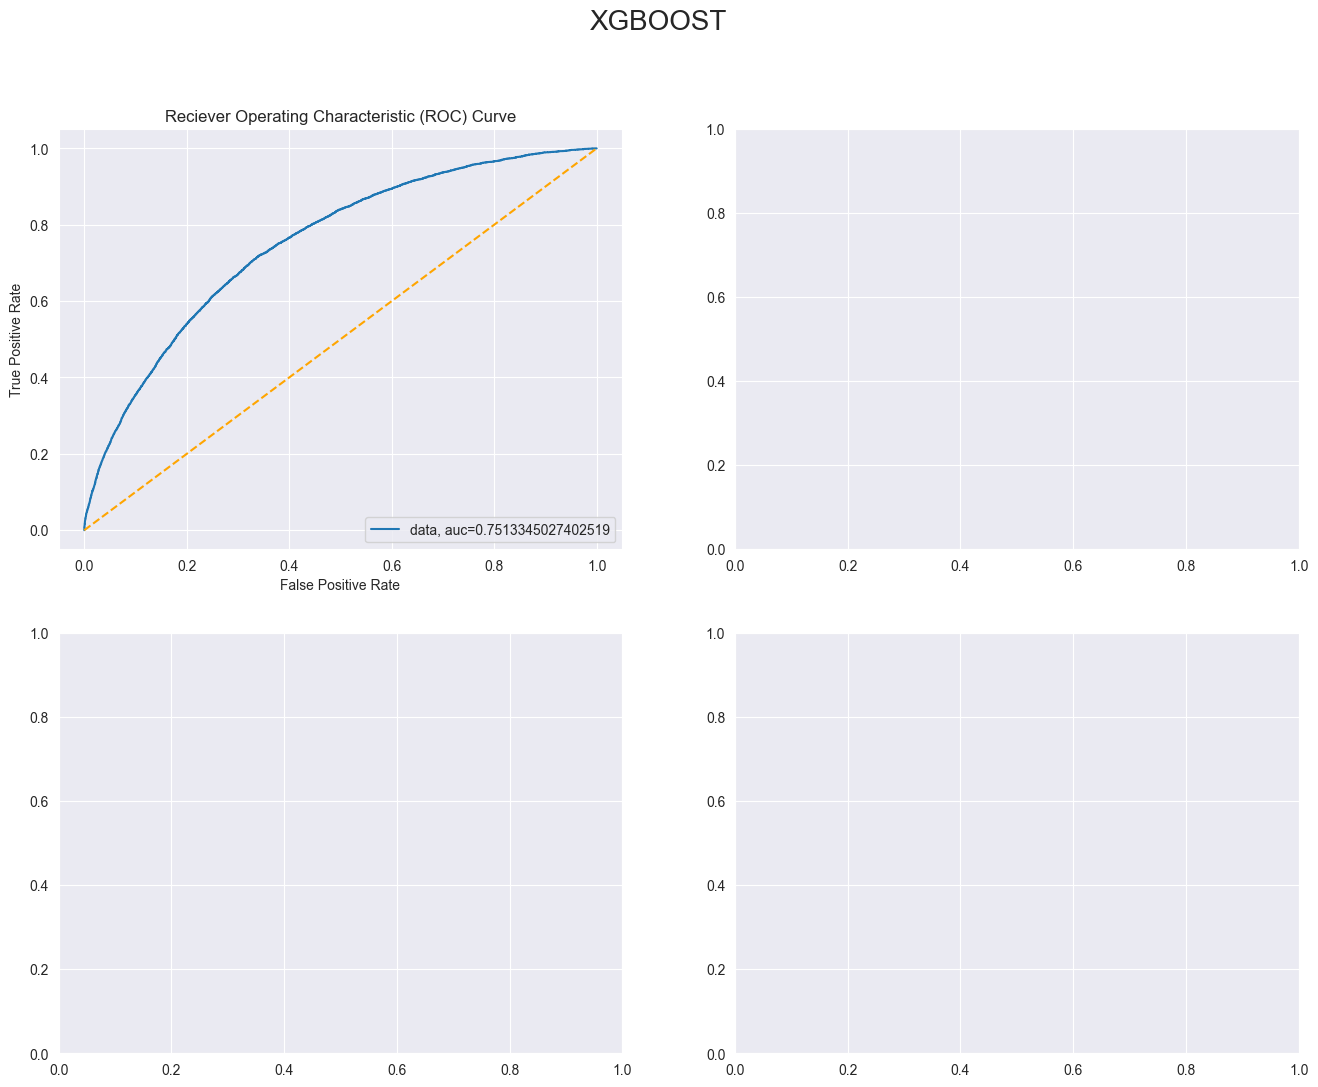

In [28]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_pred_proba = model_xgb.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("XGBOOST", fontsize = 20)
f1 = metrics.f1_score(y_test, model_xgb.predict(X_test))
print(f"f1 score: {f1}")

In [29]:
Dict_proba = {'Goal_Proba': model_xgb.predict_proba(X_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba

df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

df_proba['Goals'] = y_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

df_proba_sorted.reset_index(drop = True, inplace=True)
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted


df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.964021,100.000000,1,1,1,1.000000,0.000183
1,0.961808,99.998336,1,2,2,1.000000,0.000366
2,0.930218,99.996672,1,3,3,1.000000,0.000548
3,0.924672,99.995008,1,4,4,1.000000,0.000731
4,0.911477,99.993344,1,5,5,1.000000,0.000914
...,...,...,...,...,...,...,...
60093,0.000633,0.008320,0,5471,60094,0.091041,1.000000
60094,0.000605,0.006656,0,5471,60095,0.091039,1.000000
60095,0.000588,0.004992,0,5471,60096,0.091038,1.000000
60096,0.000579,0.003328,0,5471,60097,0.091036,1.000000


In [30]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [31]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

Text(0.5, 1.0, 'Calibration curve')

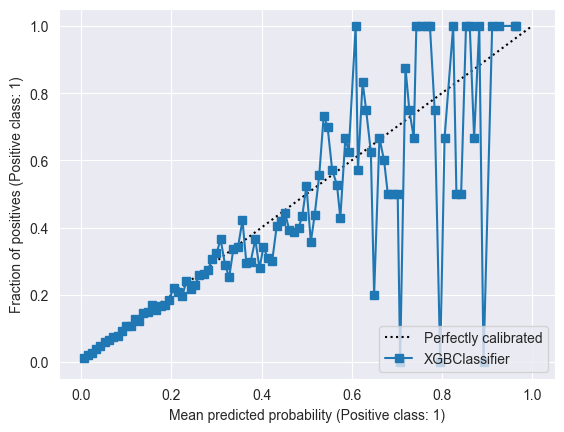

In [32]:
disp_test = CalibrationDisplay.from_estimator(model_xgb,X_test, y_test, n_bins = 105)
disp_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

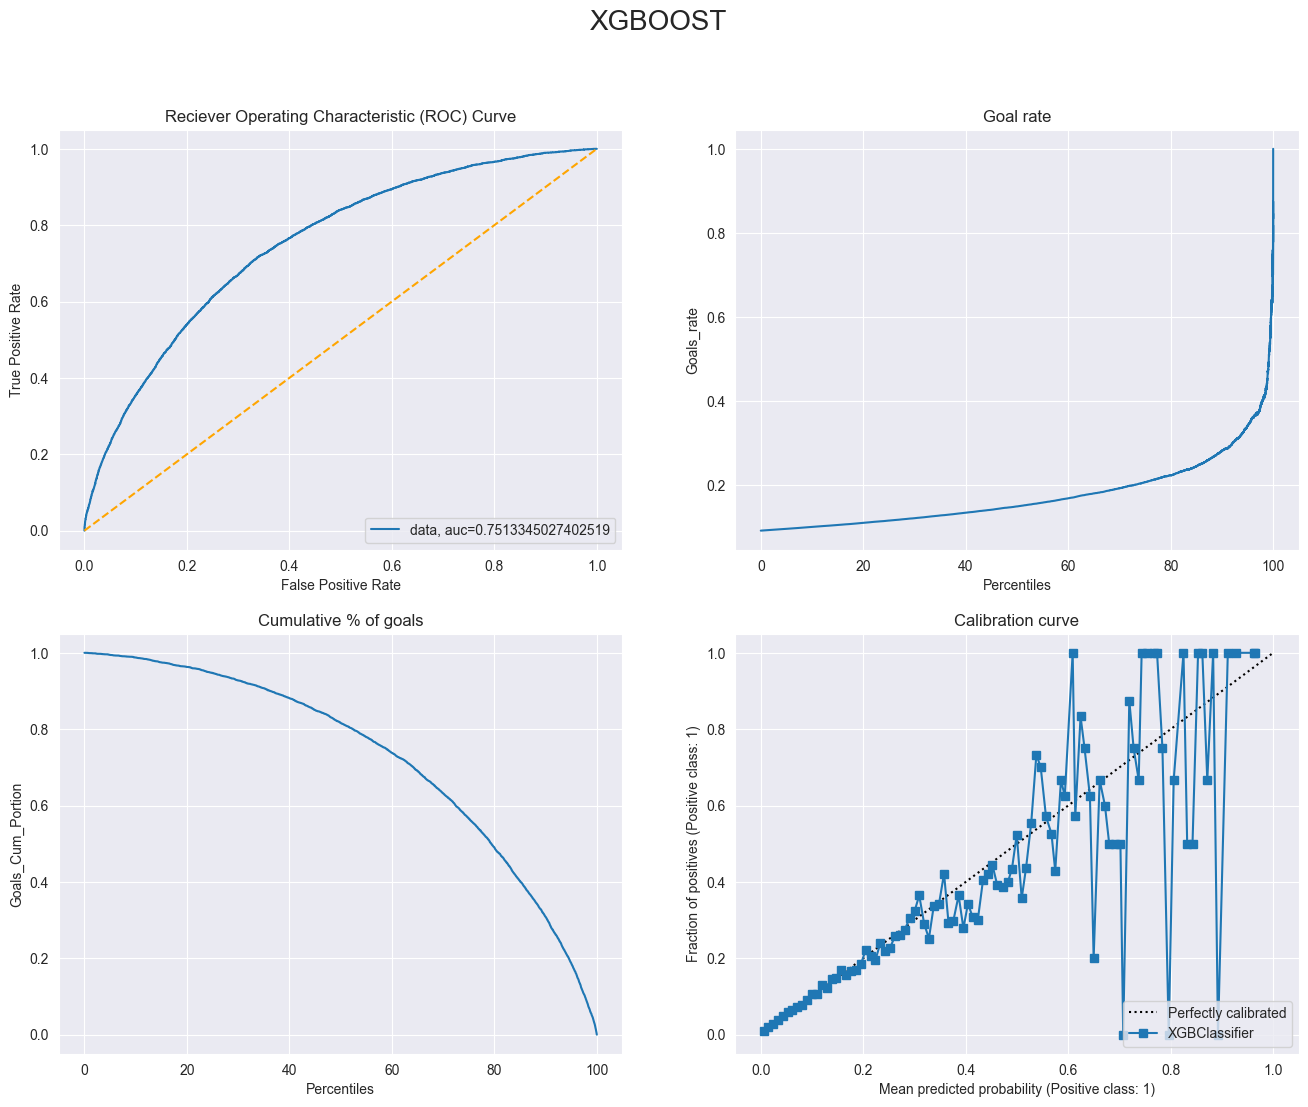

In [33]:
fig

In [34]:
X = np.hstack((my_data2[:,0].reshape(-1,1),Z,my_data2[:,12:28]))
y = my_data2[:,28]
y = y.astype('int')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=42)

# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier(tree_method="gpu_hist", max_delta_step = 1)
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train,y_train),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.96


In [35]:
df_model2[df_model2['Event_Type_Binary']==0]

,Period,Period_Time_Seconds,Time_Between_Events,X_Transformed,Last_X_Transformed,Y_Coordinate,Last_Coordinate_Y,Distance_Last_Event,Distance_Net,Rebond_Binary,...,Blocked_Shot,Faceoff,Giveaway,Goal,Hit,Missed_Shot,Penalty,Shot,Takeaway,Event_Type_Binary
0,1,51,11,55.0,-94.0,6.0,-34.0,154.275727,34.525353,0,...,0,0,0,0,1,0,0,0,0,0
1,1,65,7,79.0,37.0,0.0,-28.0,50.477718,10.000000,0,...,0,0,1,0,0,0,0,0,0,0
2,1,66,1,75.0,79.0,-1.0,0.0,4.123106,14.035669,1,...,0,0,0,0,0,0,0,1,0,0
3,1,113,18,55.0,91.0,-36.0,35.0,79.605276,49.517674,0,...,0,0,0,0,1,0,0,0,0,0
4,1,157,5,61.0,69.0,-1.0,-22.0,22.472205,28.017851,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311100,3,842,4,60.0,69.0,16.0,-22.0,39.051248,33.120990,0,...,0,1,0,0,0,0,0,0,0,0
311101,3,937,33,67.0,29.0,-19.0,35.0,66.030296,29.068884,0,...,0,0,1,0,0,0,0,0,0,0
311102,3,993,29,78.0,69.0,1.0,-22.0,24.698178,11.045361,0,...,0,1,0,0,0,0,0,0,0,0
311103,3,1119,19,82.0,71.0,10.0,4.0,12.529964,12.206556,0,...,0,0,0,0,0,1,0,0,0,0


In [36]:
df_model2[df_model2['Event_Type_Binary']!=0]

,Period,Period_Time_Seconds,Time_Between_Events,X_Transformed,Last_X_Transformed,Y_Coordinate,Last_Coordinate_Y,Distance_Last_Event,Distance_Net,Rebond_Binary,...,Blocked_Shot,Faceoff,Giveaway,Goal,Hit,Missed_Shot,Penalty,Shot,Takeaway,Event_Type_Binary
5,1,189,24,63.0,-28.0,-27.0,-39.0,91.787799,37.483330,0,...,0,0,1,0,0,0,0,0,0,1
19,2,19,6,-73.0,-93.0,-1.0,-18.0,26.248809,162.003086,0,...,0,0,0,0,0,0,1,0,0,1
57,3,722,2,67.0,39.0,0.0,13.0,30.870698,22.000000,1,...,0,0,0,0,0,0,0,1,0,1
65,3,1169,8,52.0,-69.0,4.0,-22.0,123.761868,37.215588,0,...,0,1,0,0,0,0,0,0,0,1
67,1,103,15,82.0,45.0,-21.0,-39.0,41.146081,22.135944,0,...,0,0,0,0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311060,1,675,1,82.0,82.0,2.0,4.0,2.000000,7.280110,1,...,0,0,0,0,0,0,0,1,0,1
311070,2,89,5,81.0,-61.0,-2.0,-6.0,142.056327,8.246211,0,...,1,0,0,0,0,0,0,0,0,1
311077,2,417,8,65.0,-42.0,-5.0,35.0,114.232220,24.515301,0,...,0,0,1,0,0,0,0,0,0,1
311096,3,338,5,71.0,73.0,-9.0,-1.0,8.246211,20.124612,0,...,1,0,0,0,0,0,0,0,0,1


In [48]:
from sklearn.model_selection import RandomizedSearchCV

# Quelle est la taille de cet espace de paramètres ?
tuned_parameters = {
  'gamma': np.linspace(0, 2, num=50), #50 valeurs possibles de gamma à log distance
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11)
    # 'scale_pos_weight': [0.1, 1.0]
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='f1', cv=5,  #plus iterations, plus chances trouver la bonne combinaison
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [49]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'max_depth': 0, 'max_delta_step': 6.0, 'gamma': 0.08163265306122448}
0.09253236470169321


In [50]:
model = grid_search.best_estimator_
model.fit(X_train, y_train)


XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=0.08163265306122448,
              gpu_id=0, grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_threshold=64, max_cat_to_onehot=4,
              max_delta_step=6.0, max_depth=0, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=0, ...)

In [42]:
# model = xgb.XGBClassifier(tree_method = 'gpu_hist', max_depth = 5, max_delta_step = 2, gamma = 0.16, scale_pos_weight = 0.1)
# model.fit(X_train, y_train)


XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=0.16, gpu_id=0,
              grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_threshold=64, max_cat_to_onehot=4,
              max_delta_step=2, max_depth=5, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=0, ...)

f1 score: 0.09594095940959409


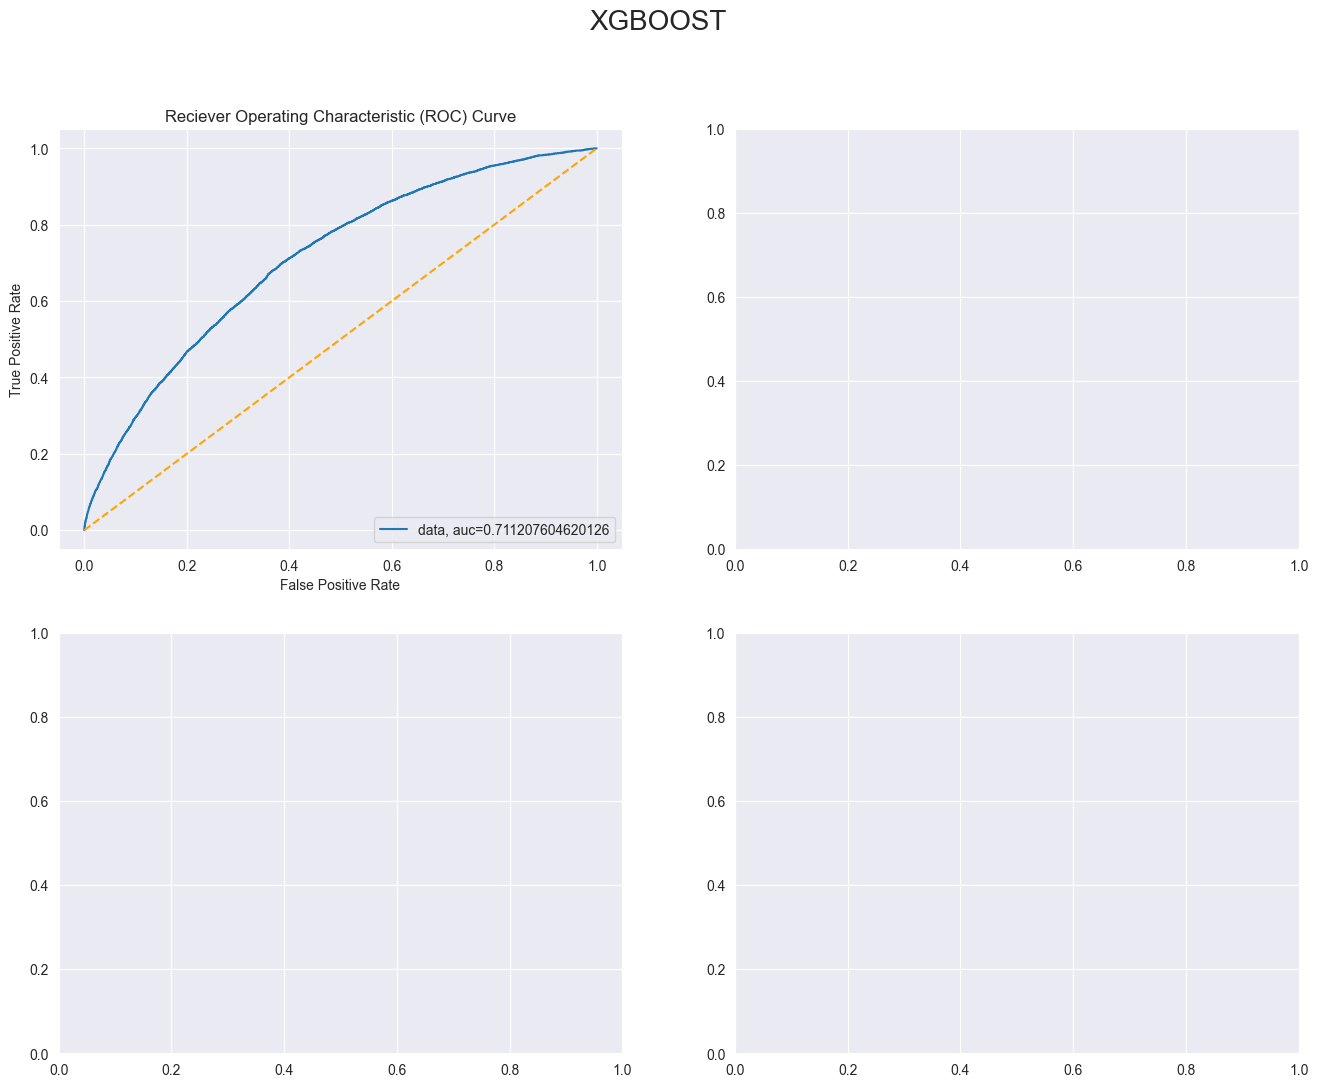

In [51]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_pred_proba = model.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("XGBOOST", fontsize = 20)
f1 = metrics.f1_score(y_test, model.predict(X_test))
print(f"f1 score: {f1}")

In [52]:
Dict_proba = {'Goal_Proba': model.predict_proba(X_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba

df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

df_proba['Goals'] = y_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

df_proba_sorted.reset_index(drop = True, inplace=True)
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted


df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.996276,100.000000,1,1,1,1.000000,0.000183
1,0.992581,99.998336,1,2,2,1.000000,0.000366
2,0.991879,99.996672,1,3,3,1.000000,0.000548
3,0.988277,99.995008,0,3,4,0.750000,0.000548
4,0.988110,99.993344,1,4,5,0.800000,0.000731
...,...,...,...,...,...,...,...
60093,0.000045,0.008320,0,5471,60094,0.091041,1.000000
60094,0.000041,0.006656,0,5471,60095,0.091039,1.000000
60095,0.000038,0.004992,0,5471,60096,0.091038,1.000000
60096,0.000033,0.003328,0,5471,60097,0.091036,1.000000


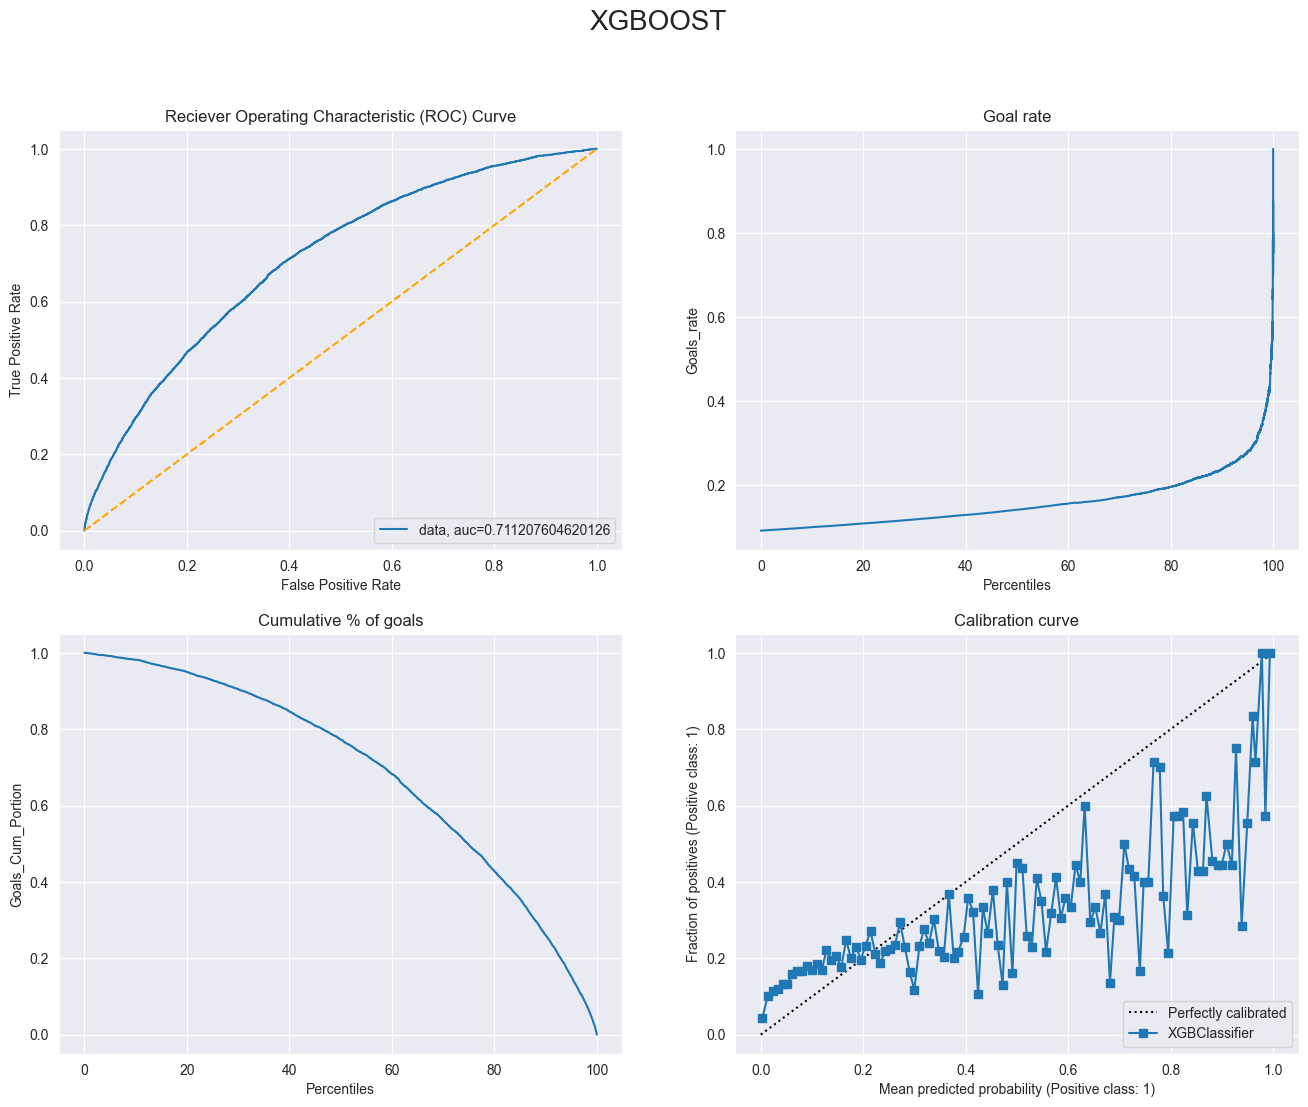

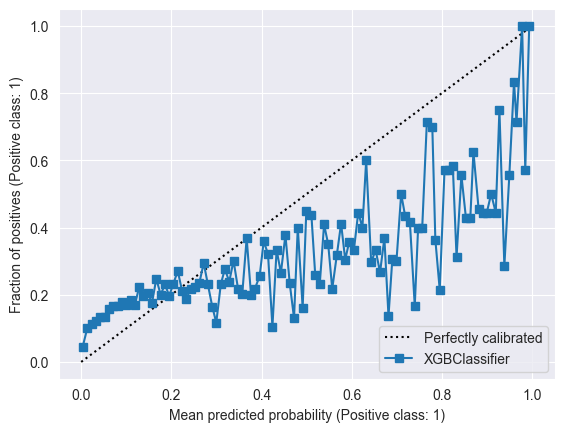

In [53]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")
disp_test = CalibrationDisplay.from_estimator(model,X_test, y_test, n_bins = 105)
disp_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")
fig